In [1]:
# Set GPU
import os
os.environ["CUDA_VISIBLE_DEVICES"]="2"

In [2]:
# List
! ls /data/nvme3/jorism/Ingenieursvak/Divason2024/models

0070_fasterrcnn_resnet50_fpn_th50	0103_resnet152_fpn_th50
0094_fasterrcnn_resnet50_fpn_deblurGAN	0104_resnet152_fpn_th50_deblurGAN
0096_resnet18_fpn_th50			0105_resnet18_fpn_th50_deblurGAN


In [3]:
from torch.utils.data import Dataset
import os, random, time
import cv2 as cv2
from matplotlib import pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import numpy as np

import torch
import torchvision
from torchvision import transforms
from torchvision import io
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection import FasterRCNN, fasterrcnn_resnet50_fpn_v2, fasterrcnn_resnet50_fpn, fasterrcnn_mobilenet_v3_large_320_fpn
from torchvision.models.detection.rpn import AnchorGenerator
import torchvision.transforms.functional as F_vision
from torchvision.utils import make_grid
from torch.utils.data import DataLoader, Dataset
from torch.utils.data.sampler import SequentialSampler
from torchvision.models.detection.backbone_utils import resnet_fpn_backbone

from tqdm.notebook import tqdm
import albumentations as A
from albumentations.pytorch import ToTensorV2
import albumentations.pytorch
import pandas as pd
from PIL import Image
import imageio
import math
from pathlib import Path
from os.path import isfile, join
import xml.etree.ElementTree as ET
import pandas as pd
import matplotlib.pyplot as plt
from torchmetrics.detection import MeanAveragePrecision
import json
import glob
import re


from config import *
from helpers import *

In [4]:
# Input
folder_models = '/data/nvme3/jorism/Ingenieursvak/Divason2024/models'

In [6]:
# Loop over model files
all_results = {}
for file_model in glob.glob(f'{folder_models}/*/modelo*.bin'):
    print()
    print(file_model)
    
    # Prepare model
    model, device, bbox_params = prepare_model(file_model, verbose=False)
    
    # Predict val set
    all_bboxes_true, all_bboxes_pred, all_scores = predict_val(folder_data, bbox_params, model, device)
    
    # Evaluate
    results = evaluate(all_bboxes_true, all_bboxes_pred, all_scores)
        
    # Append
    key = file_model.split('/')[-2]
    all_results[key] = results


/data/nvme3/jorism/Ingenieursvak/Divason2024/models/0094_fasterrcnn_resnet50_fpn_deblurGAN/modelo.bin


/home/jorism/.miniconda3/envs/pytorch_py312/lib/python3.12/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)



/data/nvme3/jorism/Ingenieursvak/Divason2024/models/0104_resnet152_fpn_th50_deblurGAN/modelo.bin

/data/nvme3/jorism/Ingenieursvak/Divason2024/models/0070_fasterrcnn_resnet50_fpn_th50/modelo.bin

/data/nvme3/jorism/Ingenieursvak/Divason2024/models/0096_resnet18_fpn_th50/modelo.bin

/data/nvme3/jorism/Ingenieursvak/Divason2024/models/0105_resnet18_fpn_th50_deblurGAN/modelo_7752.bin

/data/nvme3/jorism/Ingenieursvak/Divason2024/models/0103_resnet152_fpn_th50/modelo.bin


In [7]:
# Write results to file
with open("results.json", "w") as f:
    json.dump(all_results, f, indent=2)

In [8]:
! cat results.json

{
  "0094_fasterrcnn_resnet50_fpn_deblurGAN": {
    "map": 0.6476650834083557,
    "map_50": 0.6476650834083557,
    "map_75": -1.0,
    "map_small": -1.0,
    "map_medium": 0.6477415561676025,
    "map_large": -1.0,
    "mar_1": 0.048327136784791946,
    "mar_10": 0.33085501194000244,
    "mar_100": 0.7992565035820007,
    "mar_small": -1.0,
    "mar_medium": 0.7992565035820007,
    "mar_large": -1.0,
    "map_per_class": -1.0,
    "mar_100_per_class": -1.0,
    "classes": 1
  },
  "0104_resnet152_fpn_th50_deblurGAN": {
    "map": 0.8152980208396912,
    "map_50": 0.8152980208396912,
    "map_75": -1.0,
    "map_small": -1.0,
    "map_medium": 0.8152980208396912,
    "map_large": -1.0,
    "mar_1": 0.048327136784791946,
    "mar_10": 0.35687732696533203,
    "mar_100": 0.9182156324386597,
    "mar_small": -1.0,
    "mar_medium": 0.9182156324386597,
    "mar_large": -1.0,
    "map_per_class": -1.0,
    "mar_100_per_class": -1.0,
    "classes": 1
  },
  "0070_fasterrcnn_resnet50_fpn_th5

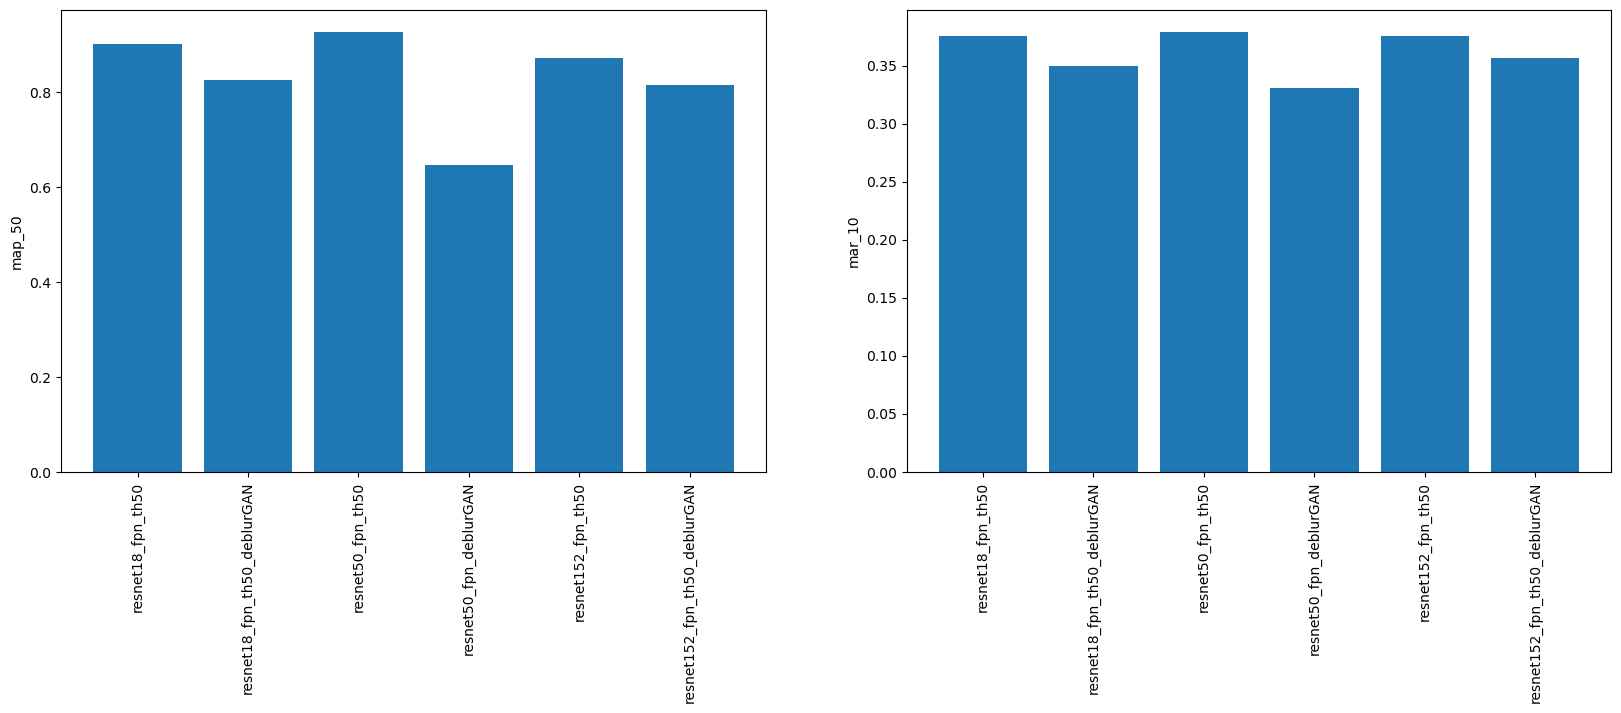

In [9]:
# Vis

keys = [
    '0096_resnet18_fpn_th50', 
    '0105_resnet18_fpn_th50_deblurGAN', 
    '0070_fasterrcnn_resnet50_fpn_th50', 
    '0094_fasterrcnn_resnet50_fpn_deblurGAN', 
    '0103_resnet152_fpn_th50',
    '0104_resnet152_fpn_th50_deblurGAN', 
]

xticks = [
    'resnet18_fpn_th50', 
    'resnet18_fpn_th50_deblurGAN', 
    'resnet50_fpn_th50', 
    'resnet50_fpn_deblurGAN', 
    'resnet152_fpn_th50',
    'resnet152_fpn_th50_deblurGAN', 
]

plt.figure(figsize=(20,6))
plt.subplot(121)
metric = 'map_50'
heights = [all_results[key][metric] for key in keys]
plt.bar(xticks, heights)
plt.xticks(rotation=90)
plt.ylabel(metric)

plt.subplot(122)
metric = 'mar_10'
heights = [all_results[key][metric] for key in keys]
plt.bar(xticks, heights)
plt.xticks(rotation=90)
plt.ylabel(metric)


plt.show()

In [53]:
# Backbone Confidence Threshold Refinement Step deblurGAN mAP mAR
rows = []
for key in keys:
    row = {}
    # row['key'] = key
    match = re.search(r"resnet[0-9]+", key)
    if match:
        backbone_name = match.group()
        row['backbone'] = (backbone_name)

    row['Confidence Threshold'] = 0.5
    row['Refinement Step'] = 'Yes'
    if 'deblurGAN' in key:
        row['deblurGAN'] = 'Yes'
    else:
        row['deblurGAN'] = 'No'

    row['mAP'] = all_results[key]['map']
    # row['mAR'] = all_results[key]['map']

    rows.append(row)

pd.DataFrame(rows)

,backbone,Confidence Threshold,Refinement Step,deblurGAN,mAP
0,resnet18,0.5,Yes,No,0.902809
1,resnet18,0.5,Yes,Yes,0.826668
2,resnet50,0.5,Yes,No,0.927313
3,resnet50,0.5,Yes,Yes,0.647665
4,resnet152,0.5,Yes,No,0.872988
5,resnet152,0.5,Yes,Yes,0.815298
